# Predicting Diabetes from Health Survey Data: Traditional ML vs Deep Learning

**Author:** YOUR NAME
**Links:** GitHub: _add link_ · Google Drive: _add link_ · Video: _add link_

This notebook trains and compares traditional machine-learning models (scikit-learn) and neural networks
(TensorFlow/Keras) on the CDC Diabetes Health Indicators dataset. The target is binary: does the respondent
report having diabetes or prediabetes (1) or not (0)?

The notebook is organised as follows:

1. Setup and reproducibility
2. Loading the data
3. Exploratory data analysis
4. Cleaning, outliers and feature engineering
5. Train / validation / test split
6. Traditional ML experiments
7. Deep learning experiments (tf.data + Keras)
8. Final evaluation on the test set
9. Error analysis
10. Saving the best models
11. Experiment table and conclusions

Every experiment is logged: scikit-learn runs go into `results/experiments.csv`, and every Keras run also writes
TensorBoard logs to `logs/`. The numbers in the report's experiment table come from those files.

## 1. Setup and reproducibility

If you are on Colab, uncomment the install line. Everything else is in `requirements.txt`.
Seeds are fixed for Python, NumPy and TensorFlow so the runs can be repeated.

In [1]:
# !pip install -q -r requirements.txt

import os, json, time, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve, classification_report)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

# Output folders
FIG_DIR, RES_DIR, MODEL_DIR, LOG_DIR = Path("figures"), Path("results"), Path("models"), Path("logs")
for d in (FIG_DIR, RES_DIR, MODEL_DIR, LOG_DIR):
    d.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
print("TensorFlow", tf.__version__)

I0000 00:00:1792435863.580585    5154 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792435863.628376    5154 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow 2.21.0


I0000 00:00:1792435865.076786    5154 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 2. Loading the data

The raw file is **not** stored in the GitHub repository (it is in the Google Drive folder instead).
Put `diabetes_binary_health_indicators_BRFSS2015.csv` in a `data/` folder next to this notebook.
If the file is not there, the cell falls back to downloading it from the UCI repository with `ucimlrepo`.

In [2]:
DATA_PATH = Path("data/diabetes_binary_health_indicators_BRFSS2015.csv")
TARGET = "Diabetes_binary"

if DATA_PATH.exists():
    df_raw = pd.read_csv(DATA_PATH)
else:
    from ucimlrepo import fetch_ucirepo          # pip install ucimlrepo
    uci = fetch_ucirepo(id=891)
    df_raw = pd.concat([uci.data.features, uci.data.targets], axis=1)

df_raw[TARGET] = df_raw[TARGET].astype(int)
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (253680, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


## 3. Exploratory data analysis

First I check types, missing values, duplicates and the class balance. These decide most of the
preprocessing choices later on.

In [3]:
print(df_raw.dtypes.value_counts(), "\n")
print("Missing values in total:", int(df_raw.isna().sum().sum()))
print("Duplicate rows:", int(df_raw.duplicated().sum()))
class_counts = df_raw[TARGET].value_counts().sort_index()
print("\nClass counts:\n", class_counts)
print("\nClass share (%):\n", (class_counts / len(df_raw) * 100).round(2))

float64    21
int64       1
Name: count, dtype: int64 

Missing values in total: 0
Duplicate rows: 24206

Class counts:
 Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64

Class share (%):
 Diabetes_binary
0    86.07
1    13.93
Name: count, dtype: float64


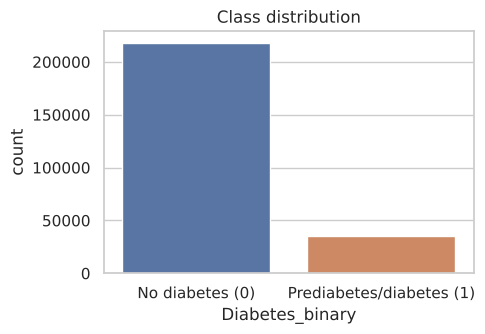

In [4]:
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(x=TARGET, data=df_raw, ax=ax, palette=["#4C72B0", "#DD8452"])
ax.set_xticklabels(["No diabetes (0)", "Prediabetes/diabetes (1)"])
ax.set_title("Class distribution")
plt.tight_layout(); plt.savefig(FIG_DIR / "class_distribution.png", dpi=150); plt.show()

The continuous-looking columns are `BMI`, `MentHlth` and `PhysHlth`. The rest are binary flags or ordinal scales
(`GenHlth` 1-5, `Age` 1-13, `Education` 1-6, `Income` 1-8). The plots below compare the two classes.

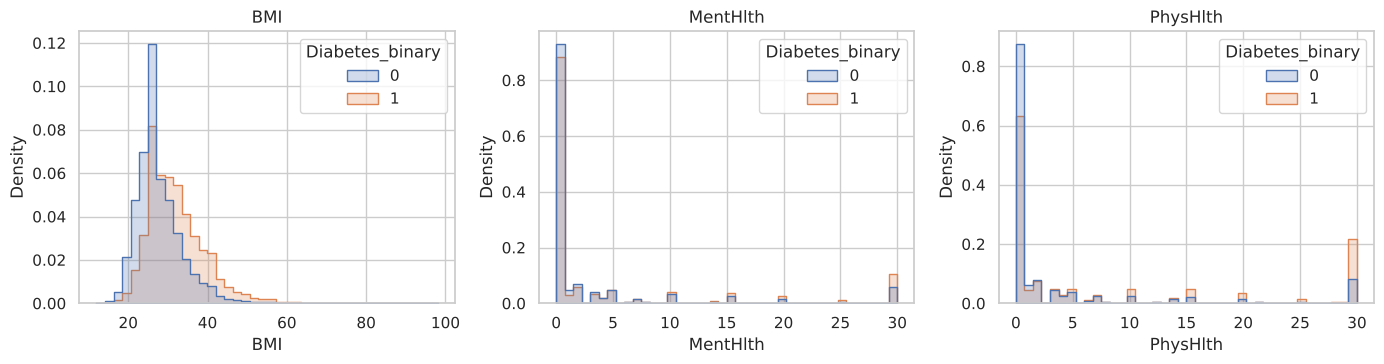

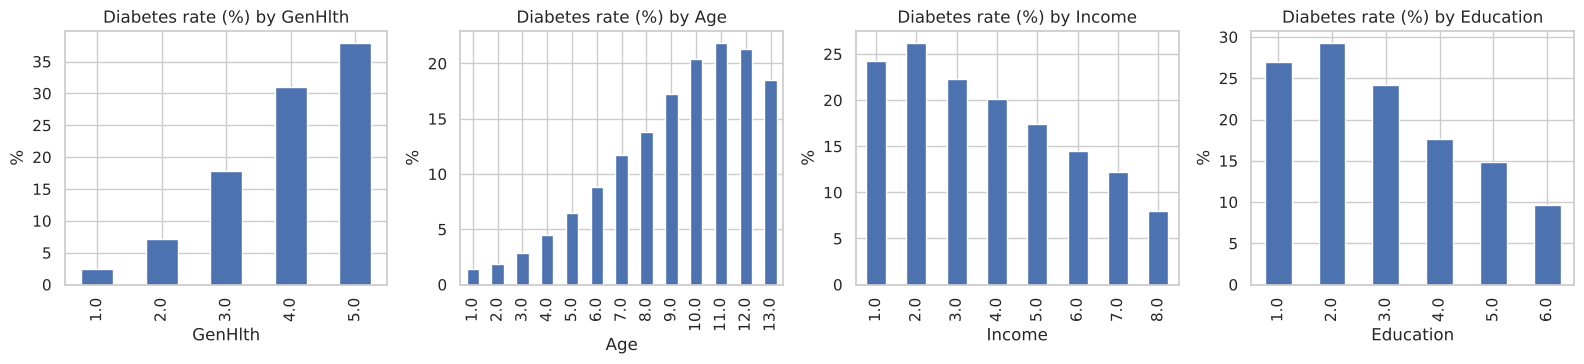

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axes, ["BMI", "MentHlth", "PhysHlth"]):
    sns.histplot(data=df_raw, x=col, hue=TARGET, bins=40, stat="density", common_norm=False, ax=ax, element="step")
    ax.set_title(col)
plt.tight_layout(); plt.savefig(FIG_DIR / "continuous_distributions.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, col in zip(axes, ["GenHlth", "Age", "Income", "Education"]):
    rate = df_raw.groupby(col)[TARGET].mean() * 100
    rate.plot(kind="bar", ax=ax, color="#4C72B0")
    ax.set_title(f"Diabetes rate (%) by {col}"); ax.set_ylabel("%")
plt.tight_layout(); plt.savefig(FIG_DIR / "rate_by_ordinal.png", dpi=150); plt.show()

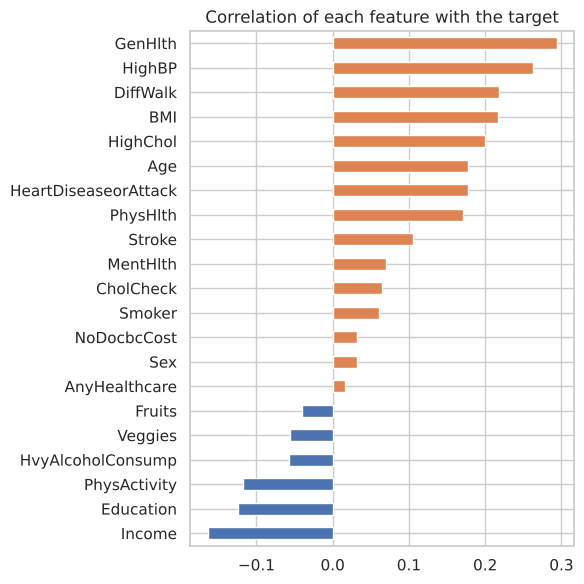

             count       mean       std   min   25%   50%   75%   max
BMI       253680.0  28.382364  6.608694  12.0  24.0  27.0  31.0  98.0
MentHlth  253680.0   3.184772  7.412847   0.0   0.0   0.0   2.0  30.0
PhysHlth  253680.0   4.242081  8.717951   0.0   0.0   0.0   3.0  30.0


In [6]:
corr = df_raw.corr()[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(6, 6))
corr.plot(kind="barh", ax=ax, color=np.where(corr > 0, "#DD8452", "#4C72B0"))
ax.set_title("Correlation of each feature with the target")
plt.tight_layout(); plt.savefig(FIG_DIR / "target_correlation.png", dpi=150); plt.show()
print(df_raw[["BMI", "MentHlth", "PhysHlth"]].describe().T)

**What the EDA tells me.** There are no missing values, but 24,206 rows (9.5%) are exact duplicates. The classes are
imbalanced: 218,334 negatives against 35,346 positives (13.9%). A model that always predicts "no diabetes" would
already reach about 86% accuracy, so accuracy is not a useful headline metric here. I report precision, recall, F1,
ROC-AUC and PR-AUC for every experiment instead. The diabetes rate climbs steadily with worse self-rated health
(`GenHlth`), with age, and with lower income. `GenHlth`, `HighBP`, `DiffWalk`, `BMI`, `HighChol` and `Age` have the
strongest correlation with the target. BMI has a long right tail that reaches 98.

## 4. Cleaning, outliers and feature engineering

* **Duplicates.** Because every answer is coded on a small scale, two different people can give identical answers,
  so duplicates are not necessarily errors. However, if identical rows land in both train and test, the test score is
  inflated. I remove exact duplicates before splitting and note this in the report.
* **Outliers.** BMI values above ~60 are rare and physiologically extreme. I cap BMI at the 99.5th percentile computed
  on the training data only (winsorising), rather than deleting rows, so no information about those people is lost.
* **Engineered features.** These come from clinical reasoning about how risk factors combine:
  * `BMI_cat` - WHO BMI bands (underweight, normal, overweight, obese I-III)
  * `CardioRisk` - count of `HighBP`, `HighChol`, `Stroke`, `HeartDiseaseorAttack`
  * `HealthyHabits` - `PhysActivity + Fruits + Veggies - Smoker - HvyAlcoholConsump`
  * `PoorHealthDays` - `MentHlth + PhysHlth` (capped at 30)
  * `Age_BMI` - interaction between age band and BMI, since weight matters more as people age
  * `NoCareAccess` - no healthcare coverage **or** couldn't afford a doctor

In [7]:
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f"Removed {len(df_raw) - len(df):,} duplicate rows -> {len(df):,} rows left")

def engineer_features(data: pd.DataFrame) -> pd.DataFrame:
    """Add the engineered features described above. Works on any frame with the original columns."""
    out = data.copy()
    out["BMI_cat"] = pd.cut(out["BMI"], bins=[0, 18.5, 25, 30, 35, 40, 200], labels=False, right=False).astype(int)
    out["CardioRisk"] = out[["HighBP", "HighChol", "Stroke", "HeartDiseaseorAttack"]].sum(axis=1)
    out["HealthyHabits"] = out["PhysActivity"] + out["Fruits"] + out["Veggies"] - out["Smoker"] - out["HvyAlcoholConsump"]
    out["PoorHealthDays"] = (out["MentHlth"] + out["PhysHlth"]).clip(upper=30)
    out["Age_BMI"] = out["Age"] * out["BMI"]
    out["NoCareAccess"] = ((out["AnyHealthcare"] == 0) | (out["NoDocbcCost"] == 1)).astype(int)
    return out

ORIGINAL_FEATURES = [c for c in df.columns if c != TARGET]

Removed 24,206 duplicate rows -> 229,474 rows left


## 5. Train / validation / test split

A stratified 70 / 15 / 15 split keeps the class ratio the same in every part. The **validation** set is used for
comparing experiments and choosing thresholds; the **test** set is only touched once, at the very end, for the two
final models. The BMI cap and the scaler are fitted on the training set only, to avoid leaking information.

In [8]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df[TARGET], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df[TARGET], random_state=SEED)

BMI_CAP = train_df["BMI"].quantile(0.995)
print(f"BMI cap (99.5th percentile of train): {BMI_CAP:.1f}")
for part in (train_df, val_df, test_df):
    part.loc[:, "BMI"] = part["BMI"].clip(upper=BMI_CAP)

train_fe, val_fe, test_fe = (engineer_features(p) for p in (train_df, val_df, test_df))
ALL_FEATURES = [c for c in train_fe.columns if c != TARGET]

y_train, y_val, y_test = (p[TARGET].values for p in (train_df, val_df, test_df))

# Two feature sets: original columns only, and original + engineered
X_train_raw, X_val_raw, X_test_raw = (p[ORIGINAL_FEATURES].values for p in (train_df, val_df, test_df))
X_train_fe, X_val_fe, X_test_fe = (p[ALL_FEATURES].values for p in (train_fe, val_fe, test_fe))

scaler_raw = StandardScaler().fit(X_train_raw)
scaler_fe = StandardScaler().fit(X_train_fe)
Xs_train_raw, Xs_val_raw, Xs_test_raw = (scaler_raw.transform(x) for x in (X_train_raw, X_val_raw, X_test_raw))
Xs_train_fe, Xs_val_fe, Xs_test_fe = (scaler_fe.transform(x) for x in (X_train_fe, X_val_fe, X_test_fe))

split_summary = pd.DataFrame({
    "rows": [len(y_train), len(y_val), len(y_test)],
    "positive %": [y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100],
}, index=["train", "validation", "test"]).round(2)
split_summary

BMI cap (99.5th percentile of train): 56.0


,rows,positive %
train,160631,15.29
validation,34421,15.29
test,34422,15.30


### Helper functions

To avoid repeating the same evaluation code for every model, these helpers compute all metrics, log each experiment
to one table, and draw the standard plots. `evaluate` uses a decision threshold of 0.5 unless told otherwise.

In [9]:
EXPERIMENTS = []

def evaluate(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred),
        "f1": f1_score(y_true, pred),
        "roc_auc": roc_auc_score(y_true, proba),
        "pr_auc": average_precision_score(y_true, proba),
    }

def log_experiment(exp_id, family, model_name, features, settings, metrics, train_time, notes=""):
    row = {"id": exp_id, "family": family, "model": model_name, "features": features,
           "settings": settings, **{k: round(v, 4) for k, v in metrics.items()},
           "train_time_s": round(train_time, 1), "notes": notes}
    EXPERIMENTS.append(row)
    pd.DataFrame(EXPERIMENTS).to_csv(RES_DIR / "experiments.csv", index=False)
    print(f"[{exp_id}] " + "  ".join(f"{k}={v:.4f}" for k, v in metrics.items()) + f"  ({train_time:.1f}s)")
    return row

def best_f1_threshold(y_true, proba):
    """Threshold on the validation set that maximises F1 (used because 0.5 is a poor default under imbalance)."""
    prec, rec, thr = precision_recall_curve(y_true, proba)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    i = np.nanargmax(f1[:-1])
    return float(thr[i]), float(f1[i])

def run_sklearn(exp_id, model, Xtr, Xva, features, settings, notes=""):
    start = time.time()
    model.fit(Xtr, y_train)
    elapsed = time.time() - start
    proba = model.predict_proba(Xva)[:, 1]
    log_experiment(exp_id, "Traditional ML", type(model).__name__, features, settings, evaluate(y_val, proba), elapsed, notes)
    return model, proba

## 6. Traditional ML experiments

Each experiment changes one thing from the one before, so the effect of that change can be read straight from the
table. All scores below are on the **validation** set.

### ML-1: Logistic Regression baseline
A plain, unweighted logistic regression on the original 21 features. This is the simplest reasonable model and the
reference point for everything else.

In [10]:
lr_base, p_ml1 = run_sklearn("ML-1", LogisticRegression(max_iter=1000, random_state=SEED),
                             Xs_train_raw, Xs_val_raw, "original (21)", "C=1.0, no class weights",
                             "baseline")

[ML-1] accuracy=0.8526  precision=0.5613  recall=0.1660  f1=0.2563  roc_auc=0.8134  pr_auc=0.4291  (0.5s)


### ML-2: Logistic Regression + class weights + engineered features
Two changes motivated by the baseline: `class_weight="balanced"` makes mistakes on the minority class cost more, and
the engineered features give the linear model non-linear information (BMI bands, interaction) it cannot build itself.

In [11]:
lr_bal, p_ml2 = run_sklearn("ML-2", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
                            Xs_train_fe, Xs_val_fe, "original + engineered (27)", "C=1.0, class_weight=balanced",
                            "tests imbalance handling + feature engineering")

[ML-2] accuracy=0.7224  precision=0.3257  recall=0.7612  f1=0.4562  roc_auc=0.8152  pr_auc=0.4312  (1.0s)


### ML-3: Random Forest (default-ish settings)
A tree ensemble can capture interactions automatically. Trees do not need scaling, so the unscaled engineered
features are used. `min_samples_leaf=5` stops the trees memorising single respondents.

In [12]:
rf_base, p_ml3 = run_sklearn("ML-3", RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1,
                                                           class_weight="balanced", random_state=SEED),
                             X_train_fe, X_val_fe, "original + engineered (27)",
                             "n_estimators=200, min_samples_leaf=5, class_weight=balanced")

[ML-3] accuracy=0.7517  precision=0.3458  recall=0.6989  f1=0.4627  roc_auc=0.8108  pr_auc=0.4271  (8.9s)


### ML-4: Random Forest tuned with randomised search
Randomised search with 3-fold stratified CV, scored on ROC-AUC. To keep it affordable the search runs on a 60,000-row
stratified sample of the training set; the best settings are then refitted on the full training set.

In [13]:
X_sub, _, y_sub, _ = train_test_split(X_train_fe, y_train, train_size=60_000, stratify=y_train, random_state=SEED)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
rf_space = {
    "n_estimators": [200, 300, 400],
    "max_depth": [8, 12, 16, 20, None],
    "min_samples_leaf": [5, 10, 20, 40],
    "max_features": ["sqrt", 0.3, 0.5],
}
rf_search = RandomizedSearchCV(RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=SEED),
                               rf_space, n_iter=12, scoring="roc_auc", cv=cv, random_state=SEED, n_jobs=1)
rf_search.fit(X_sub, y_sub)
print("Best RF params:", rf_search.best_params_, " CV ROC-AUC:", round(rf_search.best_score_, 4))
pd.DataFrame(rf_search.cv_results_)[["params", "mean_test_score", "std_test_score"]] \
  .sort_values("mean_test_score", ascending=False).to_csv(RES_DIR / "rf_search.csv", index=False)

rf_tuned, p_ml4 = run_sklearn("ML-4", RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=SEED,
                                                            **rf_search.best_params_),
                              X_train_fe, X_val_fe, "original + engineered (27)",
                              f"RandomizedSearchCV best: {rf_search.best_params_}", "tuned on 60k sample, 3-fold CV")

Best RF params: {'n_estimators': 200, 'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': 12}  CV ROC-AUC: 0.8106


[ML-4] accuracy=0.7176  precision=0.3234  recall=0.7756  f1=0.4565  roc_auc=0.8169  pr_auc=0.4406  (7.1s)


### ML-5: Histogram Gradient Boosting (default settings)
Boosting builds trees one after another, each correcting the previous ones' errors. Scikit-learn's histogram
version is fast on 200k rows and is usually the strongest model on tabular data like this.

In [14]:
hgb_base, p_ml5 = run_sklearn("ML-5", HistGradientBoostingClassifier(random_state=SEED),
                              X_train_fe, X_val_fe, "original + engineered (27)",
                              "learning_rate=0.1, max_iter=100, max_leaf_nodes=31")

[ML-5] accuracy=0.8553  precision=0.5971  recall=0.1647  f1=0.2582  roc_auc=0.8200  pr_auc=0.4463  (1.3s)


### ML-6: Gradient Boosting tuned
The search space trades off learning rate against number of trees, and controls tree size and regularisation.
Early stopping on an internal validation split prevents adding trees that no longer help.

In [15]:
hgb_space = {
    "learning_rate": [0.03, 0.05, 0.1],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [20, 50, 100],
    "l2_regularization": [0.0, 1.0, 5.0],
    "max_iter": [300, 500],
}
hgb_search = RandomizedSearchCV(HistGradientBoostingClassifier(early_stopping=True, validation_fraction=0.1,
                                                               n_iter_no_change=20, random_state=SEED),
                                hgb_space, n_iter=15, scoring="roc_auc", cv=cv, random_state=SEED, n_jobs=-1)
hgb_search.fit(X_sub, y_sub)
print("Best HGB params:", hgb_search.best_params_, " CV ROC-AUC:", round(hgb_search.best_score_, 4))
pd.DataFrame(hgb_search.cv_results_)[["params", "mean_test_score", "std_test_score"]] \
  .sort_values("mean_test_score", ascending=False).to_csv(RES_DIR / "hgb_search.csv", index=False)

hgb_tuned, p_ml6 = run_sklearn("ML-6", HistGradientBoostingClassifier(early_stopping=True, validation_fraction=0.1,
                                                                     n_iter_no_change=20, random_state=SEED,
                                                                     **hgb_search.best_params_),
                               X_train_fe, X_val_fe, "original + engineered (27)",
                               f"RandomizedSearchCV best: {hgb_search.best_params_}", "tuned on 60k sample, 3-fold CV")

Best HGB params: {'min_samples_leaf': 50, 'max_leaf_nodes': 15, 'max_iter': 300, 'learning_rate': 0.03, 'l2_regularization': 5.0}  CV ROC-AUC: 0.8148


[ML-6] accuracy=0.8547  precision=0.5860  recall=0.1702  f1=0.2638  roc_auc=0.8203  pr_auc=0.4468  (3.7s)


### ML-7: Feature selection with mutual information
Do all 27 features earn their place? I rank them by mutual information with the target (on the training sample)
and retrain the tuned boosting model on the top 15 only. If the score barely drops, the simpler model is easier to
explain and cheaper to deploy.

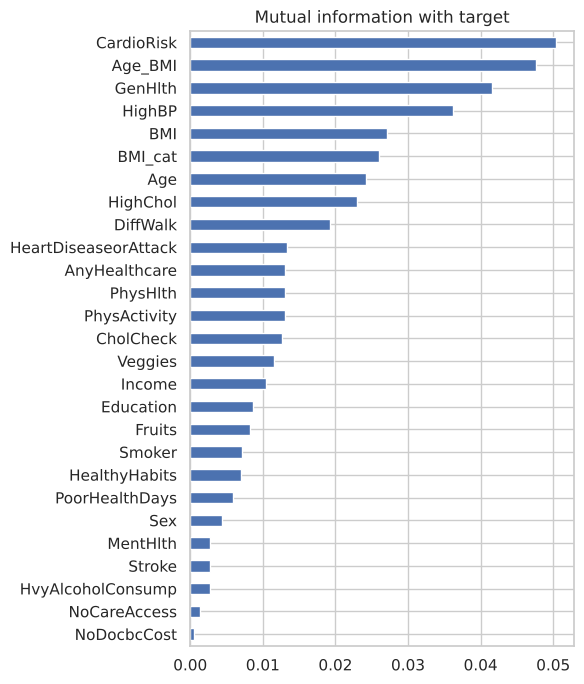

Top features: ['CardioRisk', 'Age_BMI', 'GenHlth', 'HighBP', 'BMI', 'BMI_cat', 'Age', 'HighChol', 'DiffWalk', 'HeartDiseaseorAttack', 'AnyHealthcare', 'PhysHlth', 'PhysActivity', 'CholCheck', 'Veggies']


[ML-7] accuracy=0.8544  precision=0.5891  recall=0.1596  f1=0.2511  roc_auc=0.8150  pr_auc=0.4394  (2.6s)


In [16]:
mi = pd.Series(mutual_info_classif(X_sub, y_sub, discrete_features="auto", random_state=SEED), index=ALL_FEATURES)
mi = mi.sort_values(ascending=False)
mi.to_csv(RES_DIR / "mutual_information.csv")
fig, ax = plt.subplots(figsize=(6, 7))
mi.sort_values().plot(kind="barh", ax=ax, color="#4C72B0"); ax.set_title("Mutual information with target")
plt.tight_layout(); plt.savefig(FIG_DIR / "mutual_information.png", dpi=150); plt.show()

TOP_K = 15
top_features = list(mi.index[:TOP_K])
idx = [ALL_FEATURES.index(f) for f in top_features]
print("Top features:", top_features)
hgb_sel, p_ml7 = run_sklearn("ML-7", HistGradientBoostingClassifier(early_stopping=True, validation_fraction=0.1,
                                                                   n_iter_no_change=20, random_state=SEED,
                                                                   **hgb_search.best_params_),
                             X_train_fe[:, idx], X_val_fe[:, idx], f"top {TOP_K} by mutual information",
                             "same as ML-6", "feature selection")

### ML-8: Decision threshold tuning on the best ML model
All models above use a 0.5 threshold. With 14% positives, the tuned boosting model rarely gives probabilities above
0.5, so recall is low. Here I keep the ML-6 model unchanged and only move the threshold to the value that maximises F1
on the validation set. This is a cheap but important step for a screening problem.

In [17]:
ml_thr, _ = best_f1_threshold(y_val, p_ml6)
print(f"Best-F1 threshold for ML-6: {ml_thr:.3f}")
log_experiment("ML-8", "Traditional ML", "HistGradientBoostingClassifier", "original + engineered (27)",
               f"ML-6 model, threshold={ml_thr:.3f}", evaluate(y_val, p_ml6, ml_thr), 0.0,
               "threshold moved from 0.5 to best-F1 value")
pd.DataFrame(EXPERIMENTS)[["id", "model", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]]

Best-F1 threshold for ML-6: 0.233
[ML-8] accuracy=0.7901  precision=0.3866  recall=0.6351  f1=0.4806  roc_auc=0.8203  pr_auc=0.4468  (0.0s)


,id,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,ML-1,LogisticRegression,0.8526,0.5613,0.1660,0.2563,0.8134,0.4291
1,ML-2,LogisticRegression,0.7224,0.3257,0.7612,0.4562,0.8152,0.4312
2,ML-3,RandomForestClassifier,0.7517,0.3458,0.6989,0.4627,0.8108,0.4271
3,ML-4,RandomForestClassifier,0.7176,0.3234,0.7756,0.4565,0.8169,0.4406
4,ML-5,HistGradientBoostingClassifier,0.8553,0.5971,0.1647,0.2582,0.8200,0.4463
5,ML-6,HistGradientBoostingClassifier,0.8547,0.5860,0.1702,0.2638,0.8203,0.4468
6,ML-7,HistGradientBoostingClassifier,0.8544,0.5891,0.1596,0.2511,0.8150,0.4394
7,ML-8,HistGradientBoostingClassifier,0.7901,0.3866,0.6351,0.4806,0.8203,0.4468


### Learning curve for the best traditional model
The learning curve shows training and cross-validated ROC-AUC as the training set grows. A large, persistent gap
means high variance (overfitting); two low curves that meet mean high bias (underfitting).

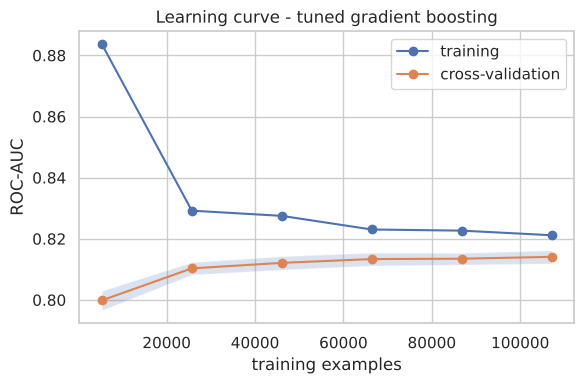

In [18]:
sizes, tr_scores, cv_scores = learning_curve(
    HistGradientBoostingClassifier(random_state=SEED, **{k: v for k, v in hgb_search.best_params_.items()}),
    X_train_fe, y_train, train_sizes=np.linspace(0.05, 1.0, 6), cv=cv, scoring="roc_auc", n_jobs=-1)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(sizes, tr_scores.mean(1), "o-", label="training")
ax.plot(sizes, cv_scores.mean(1), "o-", label="cross-validation")
ax.fill_between(sizes, cv_scores.mean(1) - cv_scores.std(1), cv_scores.mean(1) + cv_scores.std(1), alpha=0.2)
ax.set_xlabel("training examples"); ax.set_ylabel("ROC-AUC"); ax.set_title("Learning curve - tuned gradient boosting")
ax.legend(); plt.tight_layout(); plt.savefig(FIG_DIR / "learning_curve_hgb.png", dpi=150); plt.show()
pd.DataFrame({"train_size": sizes, "train_auc": tr_scores.mean(1), "cv_auc": cv_scores.mean(1)}) \
  .round(4).to_csv(RES_DIR / "learning_curve_hgb.csv", index=False)

**Reading the ML results.** All the tree and linear models end up with very similar ROC-AUC (about 0.81-0.82), so the
ranking quality is limited more by the information in the survey answers than by the choice of algorithm. Class
weighting (ML-2, ML-3, ML-4) hardly changes AUC, but it moves recall from about 0.17 to about 0.70-0.78, because it
mainly shifts where the decision boundary sits. Threshold tuning (ML-8) does the same job for the boosting model
without retraining. Keeping only the top 15 features (ML-7) costs about 0.005 AUC.

In the learning curve, the training and CV scores converge (from a gap of about 0.08 with 5k rows to under 0.01 at full
size), and the CV curve has almost flattened. That is a high-bias picture: more rows of the same kind would add very
little. Better features would help more.

## 7. Deep learning experiments (tf.data + Keras)

All neural networks read data through a `tf.data` pipeline: the arrays are wrapped in a `Dataset`, shuffled with a
fixed seed, batched and prefetched so the CPU prepares the next batch while the current one trains.
Every run logs to TensorBoard (`logs/<run id>`) and uses the same validation set as the ML models.
Unless stated, runs use the scaled original + engineered features, Adam, binary cross-entropy, and up to 40 epochs.

In [19]:
def make_dataset(X, y, batch_size=512, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X.astype("float32"), y.astype("float32")))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(y), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

def build_mlp(n_features, units=(64, 32), dropout=0.0, l2=0.0, batch_norm=False, lr=1e-3):
    """Sequential API multilayer perceptron."""
    model = keras.Sequential([keras.Input(shape=(n_features,))])
    for u in units:
        model.add(layers.Dense(u, kernel_regularizer=regularizers.l2(l2) if l2 else None))
        if batch_norm:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        if dropout:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="auc"), keras.metrics.Recall(name="recall"),
                           keras.metrics.Precision(name="precision")])
    return model

CLASS_WEIGHT = {0: 1.0, 1: float((y_train == 0).sum() / (y_train == 1).sum())}
print("Class weight for positives:", round(CLASS_WEIGHT[1], 2))
HISTORIES = {}

def run_keras(exp_id, model, Xtr, Xva, settings, epochs=40, batch_size=512, class_weight=None,
              early_stop=True, extra_callbacks=(), notes="", train_inputs=None, val_inputs=None):
    keras.utils.set_random_seed(SEED)
    tr_ds = train_inputs if train_inputs is not None else make_dataset(Xtr, y_train, batch_size, shuffle=True)
    va_ds = val_inputs if val_inputs is not None else make_dataset(Xva, y_val, batch_size)
    callbacks = [keras.callbacks.TensorBoard(log_dir=str(LOG_DIR / exp_id))] + list(extra_callbacks)
    if early_stop:
        callbacks.append(keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6,
                                                       restore_best_weights=True))
    start = time.time()
    hist = model.fit(tr_ds, validation_data=va_ds, epochs=epochs, class_weight=class_weight,
                     callbacks=callbacks, verbose=0)
    elapsed = time.time() - start
    HISTORIES[exp_id] = hist.history
    proba = model.predict(va_ds, verbose=0).ravel()
    n_ep = len(hist.history["loss"])
    log_experiment(exp_id, "Deep Learning", model.name, "scaled original + engineered (27)",
                   f"{settings}; epochs run={n_ep}; batch={batch_size}", evaluate(y_val, proba), elapsed, notes)
    return model, proba

def plot_history(exp_ids, fname):
    fig, axes = plt.subplots(1, len(exp_ids), figsize=(4.2 * len(exp_ids), 3.5), squeeze=False)
    for ax, eid in zip(axes[0], exp_ids):
        h = HISTORIES[eid]
        ax.plot(h["loss"], label="train loss"); ax.plot(h["val_loss"], label="val loss")
        ax.set_title(eid); ax.set_xlabel("epoch"); ax.legend()
    plt.tight_layout(); plt.savefig(FIG_DIR / fname, dpi=150); plt.show()

N_FE = Xs_train_fe.shape[1]

Class weight for positives: 5.54


### DL-1: Small MLP baseline
Two hidden layers (64, 32), no regularisation, no class weights, learning rate 0.001. Early stopping is switched
**off** and it trains for the full 40 epochs, so the learning curve shows what happens without any control.

In [20]:
_, p_dl1 = run_keras("DL-1", build_mlp(N_FE),
                     Xs_train_fe, Xs_val_fe, "Sequential 64-32, lr=1e-3, no reg", early_stop=False, notes="baseline")

[DL-1] accuracy=0.8520  precision=0.5424  recall=0.2065  f1=0.2991  roc_auc=0.8143  pr_auc=0.4310  (58.1s)


### DL-2: Bigger network, still no regularisation
Three wider layers (256-128-64). With more capacity and no regularisation, I expect training loss to keep falling
while validation loss rises: classic overfitting.

In [21]:
_, p_dl2 = run_keras("DL-2", build_mlp(N_FE, units=(256, 128, 64)), Xs_train_fe, Xs_val_fe,
                     "Sequential 256-128-64, lr=1e-3, no reg", early_stop=False, notes="capacity test")

[DL-2] accuracy=0.8329  precision=0.4144  recall=0.2249  f1=0.2916  roc_auc=0.7606  pr_auc=0.3404  (86.6s)


### DL-3: Same network with dropout, L2 and batch normalisation, plus early stopping
Dropout (0.3) and a small L2 penalty (1e-4) fight the overfitting seen in DL-2; batch normalisation stabilises
training. Early stopping keeps the weights from the epoch with the best validation AUC.

In [22]:
mlp_reg, p_dl3 = run_keras("DL-3", build_mlp(N_FE, units=(256, 128, 64), dropout=0.3, l2=1e-4, batch_norm=True),
                     Xs_train_fe, Xs_val_fe, "256-128-64, dropout=0.3, L2=1e-4, BatchNorm, early stop",
                     notes="regularisation")

[DL-3] accuracy=0.8532  precision=0.6677  recall=0.0802  f1=0.1431  roc_auc=0.8198  pr_auc=0.4448  (86.0s)


### DL-4: High learning rate (0.01)
Same as DL-3 but with a learning rate ten times larger, to see how sensitive training is to step size.

In [23]:
_, p_dl4 = run_keras("DL-4", build_mlp(N_FE, units=(256, 128, 64), dropout=0.3, l2=1e-4, batch_norm=True, lr=1e-2),
                     Xs_train_fe, Xs_val_fe, "as DL-3 but lr=1e-2", notes="learning-rate sensitivity")

[DL-4] accuracy=0.8539  precision=0.6450  recall=0.0997  f1=0.1728  roc_auc=0.8170  pr_auc=0.4368  (33.0s)


### DL-5: Class-weighted loss
DL-3 again, but positive examples count about six times more in the loss. This should raise recall at the cost of
precision, similar to `class_weight="balanced"` in ML-2.

In [24]:
mlp_cw, p_dl5 = run_keras("DL-5", build_mlp(N_FE, units=(256, 128, 64), dropout=0.3, l2=1e-4, batch_norm=True),
                     Xs_train_fe, Xs_val_fe, f"as DL-3 + class_weight={{1: {CLASS_WEIGHT[1]:.2f}}}",
                     class_weight=CLASS_WEIGHT, notes="imbalance handling")

[DL-5] accuracy=0.7150  precision=0.3233  recall=0.7897  f1=0.4587  roc_auc=0.8198  pr_auc=0.4436  (86.7s)


### DL-6: Functional API "wide and deep" model with embeddings
The ordinal variables (`GenHlth`, `Age`, `Education`, `Income`, `BMI_cat`) are treated as categories and given small
learned embeddings, so the network can learn that, for example, age band 9 is not simply "9 times" age band 1.
A wide linear path on all numeric inputs is concatenated with the deep path (idea from Cheng et al., 2016).
Learning rate is reduced on plateau. This model needs several inputs, so the tf.data pipeline yields a dictionary.

In [25]:
CAT_COLS = ["GenHlth", "Age", "Education", "Income", "BMI_cat"]
NUM_COLS = [c for c in ALL_FEATURES if c not in CAT_COLS]
num_scaler = StandardScaler().fit(train_fe[NUM_COLS].values)
cat_offsets = {c: int(train_fe[c].min()) for c in CAT_COLS}
cat_sizes = {c: int(train_fe[c].max()) - cat_offsets[c] + 2 for c in CAT_COLS}

def to_inputs(frame):
    d = {"num": num_scaler.transform(frame[NUM_COLS].values).astype("float32")}
    for c in CAT_COLS:
        d[c] = np.clip(frame[c].values - cat_offsets[c], 0, cat_sizes[c] - 1).astype("int32")
    return d

def make_dict_dataset(frame, y, batch_size=512, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((to_inputs(frame), y.astype("float32")))
    if shuffle:
        ds = ds.shuffle(len(y), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

def build_wide_deep(lr=1e-3, emb_dim=4, units=(128, 64), dropout=0.3, l2=1e-4):
    num_in = keras.Input(shape=(len(NUM_COLS),), name="num")
    cat_ins, embs = [], []
    for c in CAT_COLS:
        inp = keras.Input(shape=(), dtype="int32", name=c)
        cat_ins.append(inp)
        embs.append(layers.Embedding(cat_sizes[c], emb_dim, name=f"emb_{c}")(inp))
    deep = layers.Concatenate()([num_in] + embs)
    for u in units:
        deep = layers.Dense(u, kernel_regularizer=regularizers.l2(l2))(deep)
        deep = layers.BatchNormalization()(deep)
        deep = layers.Activation("relu")(deep)
        deep = layers.Dropout(dropout)(deep)
    wide = layers.Dense(1)(num_in)
    out = layers.Activation("sigmoid")(layers.Add()([layers.Dense(1)(deep), wide]))
    model = keras.Model([num_in] + cat_ins, out, name="wide_and_deep")
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="auc"), keras.metrics.Recall(name="recall"),
                           keras.metrics.Precision(name="precision")])
    return model

wd_train_ds = make_dict_dataset(train_fe, y_train, shuffle=True)
wd_val_ds = make_dict_dataset(val_fe, y_val)
reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max", factor=0.5, patience=3, min_lr=1e-5)
wide_deep, p_dl6 = run_keras("DL-6", build_wide_deep(), None, None,
                             "Functional wide&deep, emb_dim=4, 128-64, dropout=0.3, L2=1e-4, ReduceLROnPlateau",
                             extra_callbacks=[reduce_lr], train_inputs=wd_train_ds, val_inputs=wd_val_ds,
                             notes="embeddings for ordinal features")

[DL-6] accuracy=0.8554  precision=0.5960  recall=0.1693  f1=0.2636  roc_auc=0.8201  pr_auc=0.4458  (93.9s)


### DL-7: Wide and deep with a larger batch size
Batch size 2048 instead of 512, with the learning rate doubled to compensate. Larger batches give smoother but fewer
gradient updates per epoch; this tests whether training can be made faster without losing accuracy.

In [26]:
wd_train_big = make_dict_dataset(train_fe, y_train, batch_size=2048, shuffle=True)
wd_val_big = make_dict_dataset(val_fe, y_val, batch_size=2048)
reduce_lr2 = keras.callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max", factor=0.5, patience=3, min_lr=1e-5)
wide_deep_big, p_dl7 = run_keras("DL-7", build_wide_deep(lr=2e-3), None, None,
                                 "as DL-6 but batch=2048, lr=2e-3", batch_size=2048,
                                 extra_callbacks=[reduce_lr2], train_inputs=wd_train_big, val_inputs=wd_val_big,
                                 notes="batch-size / speed trade-off")

[DL-7] accuracy=0.8554  precision=0.6059  recall=0.1554  f1=0.2474  roc_auc=0.8199  pr_auc=0.4455  (76.3s)


### DL-8: Threshold tuning on the best neural network
As in ML-8, the trained model is unchanged; only the decision threshold moves to the best-F1 value on validation.

In [27]:
dl_results = {"DL-3": p_dl3, "DL-5": p_dl5, "DL-6": p_dl6, "DL-7": p_dl7}
# model object and input type ("flat" array or "dict" for the wide-and-deep model) for each candidate
dl_models = {"DL-3": (mlp_reg, "flat"), "DL-5": (mlp_cw, "flat"), "DL-6": (wide_deep, "dict"),
             "DL-7": (wide_deep_big, "dict")}
best_dl_id = max(dl_results, key=lambda k: roc_auc_score(y_val, dl_results[k]))
dl_thr, _ = best_f1_threshold(y_val, dl_results[best_dl_id])
print(f"Best DL run by validation ROC-AUC: {best_dl_id}; best-F1 threshold = {dl_thr:.3f}")
log_experiment("DL-8", "Deep Learning", f"{best_dl_id} model", "as " + best_dl_id,
               f"{best_dl_id} model, threshold={dl_thr:.3f}", evaluate(y_val, dl_results[best_dl_id], dl_thr), 0.0,
               "threshold moved from 0.5 to best-F1 value")

Best DL run by validation ROC-AUC: DL-6; best-F1 threshold = 0.257
[DL-8] accuracy=0.7943  precision=0.3899  recall=0.6115  f1=0.4762  roc_auc=0.8201  pr_auc=0.4458  (0.0s)


{'id': 'DL-8',
 'family': 'Deep Learning',
 'model': 'DL-6 model',
 'features': 'as DL-6',
 'settings': 'DL-6 model, threshold=0.257',
 'accuracy': 0.7943,
 'precision': 0.3899,
 'recall': 0.6115,
 'f1': 0.4762,
 'roc_auc': 0.8201,
 'pr_auc': 0.4458,
 'train_time_s': 0.0,
 'notes': 'threshold moved from 0.5 to best-F1 value'}

### Learning curves (loss per epoch)
Training versus validation loss for the main runs. The gap between the two lines is the visual evidence for
over- or underfitting that the report discusses.

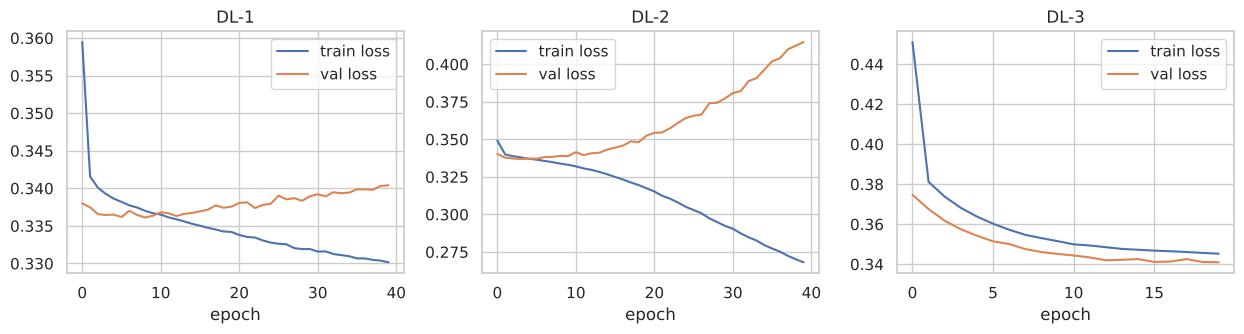

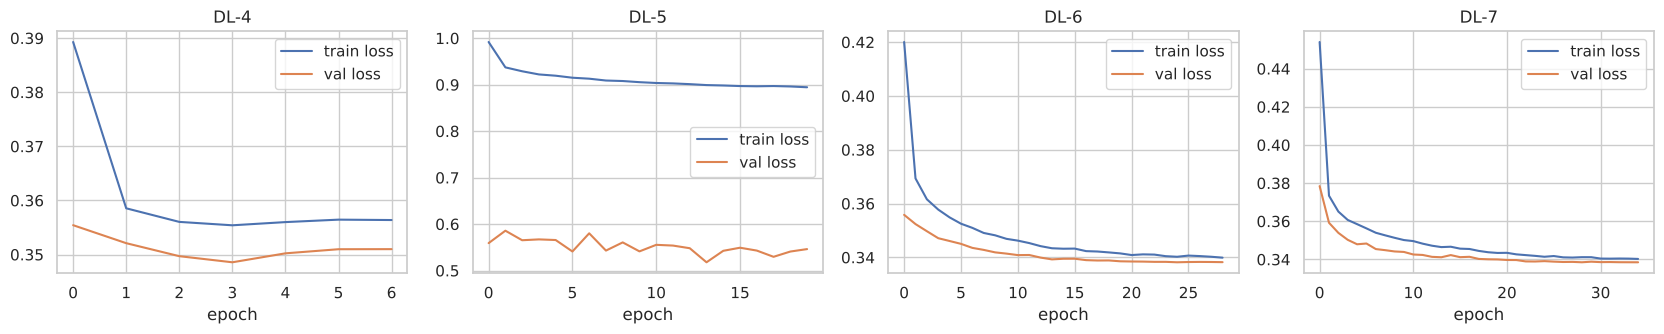

In [28]:
plot_history(["DL-1", "DL-2", "DL-3"], "dl_learning_curves_1.png")
plot_history(["DL-4", "DL-5", "DL-6", "DL-7"], "dl_learning_curves_2.png")
for eid, h in HISTORIES.items():
    pd.DataFrame(h).to_csv(RES_DIR / f"history_{eid}.csv", index_label="epoch")

**Reading the DL curves.** In DL-1 the validation loss bottoms out after about 5 epochs and then creeps up while the
training loss keeps falling: mild overfitting. In DL-2 (bigger network, no regularisation) the effect is dramatic.
Training loss drops to about 0.27 while validation loss climbs past 0.41, and validation AUC falls from 0.818 at its
best epoch to 0.761 at the end. With dropout, L2, batch norm and early stopping (DL-3), the validation loss tracks the
training loss and ends slightly *below* it, because dropout is switched off at evaluation time. The large learning rate
(DL-4) reached its best validation AUC in the very first epoch and never improved after that, so early stopping ended
it at epoch 7. The step size was too big to settle into a good minimum. The wide-and-deep model (DL-6) gives the best
validation AUC of the neural networks, but only by a few thousandths.

## 8. Final evaluation on the test set

The best model from each family (chosen on **validation** ROC-AUC) is evaluated once on the untouched test set, using
the threshold chosen on validation. Results are shown at both 0.5 and the tuned threshold.

In [29]:
exp_table = pd.DataFrame(EXPERIMENTS)
print(exp_table[["id", "model", "f1", "roc_auc", "pr_auc"]].to_string(index=False))

best_ml_model = hgb_tuned
ml_test_proba = best_ml_model.predict_proba(X_test_fe)[:, 1]
best_dl_model, dl_input_kind = dl_models[best_dl_id]
dl_test_ds = make_dict_dataset(test_fe, y_test) if dl_input_kind == "dict" else make_dataset(Xs_test_fe, y_test)
dl_test_proba = best_dl_model.predict(dl_test_ds, verbose=0).ravel()

final_rows = []
for name, proba, thr in [("Gradient Boosting (ML-6)", ml_test_proba, ml_thr),
                         (f"Neural net ({best_dl_id})", dl_test_proba, dl_thr)]:
    for t in (0.5, thr):
        final_rows.append({"model": name, "threshold": round(t, 3), **{k: round(v, 4) for k, v in evaluate(y_test, proba, t).items()}})
final_table = pd.DataFrame(final_rows)
final_table.to_csv(RES_DIR / "final_test_results.csv", index=False)
final_table

  id                          model     f1  roc_auc  pr_auc
ML-1             LogisticRegression 0.2563   0.8134  0.4291
ML-2             LogisticRegression 0.4562   0.8152  0.4312
ML-3         RandomForestClassifier 0.4627   0.8108  0.4271
ML-4         RandomForestClassifier 0.4565   0.8169  0.4406
ML-5 HistGradientBoostingClassifier 0.2582   0.8200  0.4463
ML-6 HistGradientBoostingClassifier 0.2638   0.8203  0.4468
ML-7 HistGradientBoostingClassifier 0.2511   0.8150  0.4394
ML-8 HistGradientBoostingClassifier 0.4806   0.8203  0.4468
DL-1                     sequential 0.2991   0.8143  0.4310
DL-2                   sequential_1 0.2916   0.7606  0.3404
DL-3                   sequential_2 0.1431   0.8198  0.4448
DL-4                   sequential_3 0.1728   0.8170  0.4368
DL-5                   sequential_4 0.4587   0.8198  0.4436
DL-6                  wide_and_deep 0.2636   0.8201  0.4458
DL-7                  wide_and_deep 0.2474   0.8199  0.4455
DL-8                     DL-6 model 0.47

,model,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Gradient Boosting (ML-6),0.500,0.8544,0.5841,0.1670,0.2597,0.8169,0.4383
1,Gradient Boosting (ML-6),0.233,0.7872,0.3807,0.6243,0.4729,0.8169,0.4383
2,Neural net (DL-6),0.500,0.8539,0.5804,0.1624,0.2538,0.8174,0.4386
3,Neural net (DL-6),0.257,0.7924,0.3862,0.6059,0.4717,0.8174,0.4386


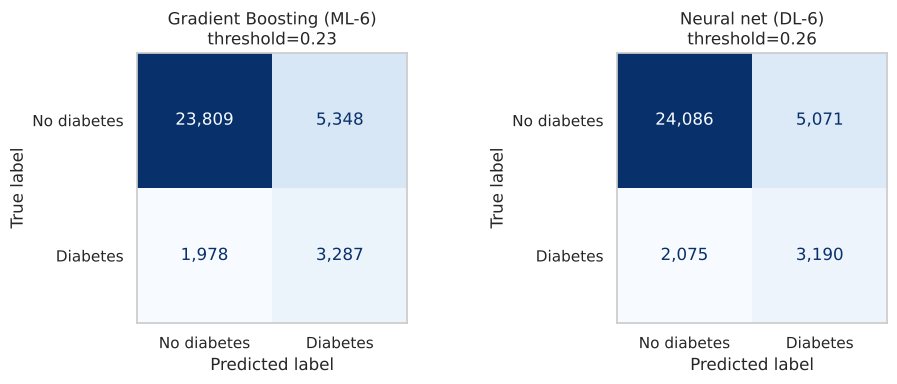

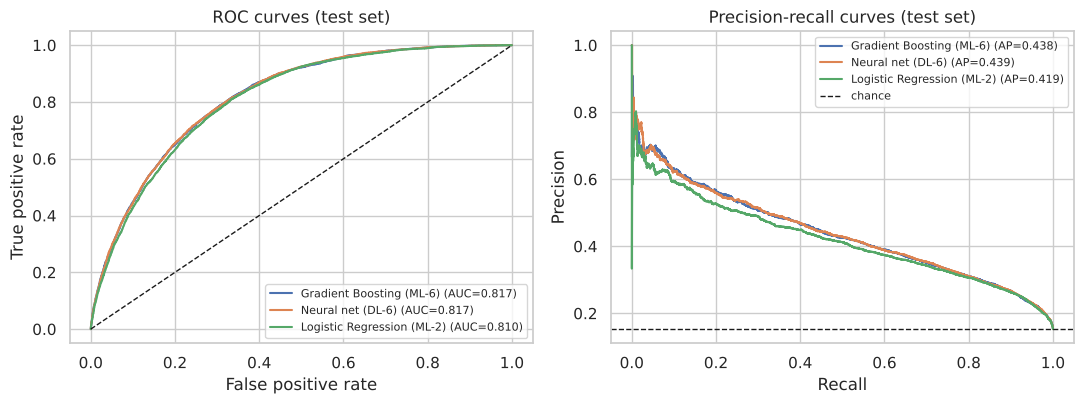

              precision    recall  f1-score   support

 No diabetes      0.923     0.817     0.867     29157
    Diabetes      0.381     0.624     0.473      5265

    accuracy                          0.787     34422
   macro avg      0.652     0.720     0.670     34422
weighted avg      0.840     0.787     0.806     34422



In [30]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, proba, thr) in zip(axes, [("Gradient Boosting (ML-6)", ml_test_proba, ml_thr),
                                         (f"Neural net ({best_dl_id})", dl_test_proba, dl_thr)]):
    cm = confusion_matrix(y_test, (proba >= thr).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["No diabetes", "Diabetes"]).plot(ax=ax, values_format=",", colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\nthreshold={thr:.2f}"); ax.grid(False)
plt.tight_layout(); plt.savefig(FIG_DIR / "confusion_matrices.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for name, proba in [("Gradient Boosting (ML-6)", ml_test_proba), (f"Neural net ({best_dl_id})", dl_test_proba),
                    ("Logistic Regression (ML-2)", lr_bal.predict_proba(Xs_test_fe)[:, 1])]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, label=f"{name} (AP={average_precision_score(y_test, proba):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curves (test set)"); axes[0].legend(fontsize=8)
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label="chance")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-recall curves (test set)")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "roc_pr_curves.png", dpi=150); plt.show()

print(classification_report(y_test, (ml_test_proba >= ml_thr).astype(int), target_names=["No diabetes", "Diabetes"], digits=3))

**Reading the test results.** On the untouched test set, the two finalists are practically tied (ROC-AUC about 0.817 for
both, PR-AUC about 0.438). Both ROC curves lie almost on top of the logistic-regression curve. At the tuned threshold,
the boosting model finds about 62% of diabetics, and roughly 38% of the people it flags actually have diabetes.
Compare that with the 0.5 threshold, where recall is only about 17%. The PR-AUC of about 0.44 is roughly three times
the 0.15 a random model would get (the positive share after removing duplicates), but it shows that precision stays modest at any useful recall.

## 9. Error analysis

Which people does the best model get wrong? I split the test set into true positives, false negatives (missed
diabetics), false positives and true negatives, and compare their average profile. I also check how recall changes
across age and BMI groups, because a screening tool that only works for older or heavier people would be biased.

In [31]:
pred_ml = (ml_test_proba >= ml_thr).astype(int)
err = test_fe.copy()
err["pred"] = pred_ml
err["group"] = np.select([(err[TARGET] == 1) & (err.pred == 1), (err[TARGET] == 1) & (err.pred == 0),
                          (err[TARGET] == 0) & (err.pred == 1)], ["TP", "FN", "FP"], "TN")
profile_cols = ["GenHlth", "HighBP", "HighChol", "BMI", "Age", "DiffWalk", "CardioRisk", "PhysActivity", "Income"]
profile = err.groupby("group")[profile_cols].mean().loc[["TP", "FN", "FP", "TN"]].round(2)
profile["count"] = err["group"].value_counts()
profile.to_csv(RES_DIR / "error_profile.csv")
profile

,GenHlth,HighBP,HighChol,BMI,Age,DiffWalk,CardioRisk,PhysActivity,Income,count
group,,,,,,,,,,
TP,3.68,0.90,0.78,34.04,9.66,0.50,2.11,0.58,4.80,3287
FN,2.66,0.53,0.48,28.61,8.85,0.16,1.12,0.72,5.78,1978
FP,3.48,0.87,0.73,32.55,9.78,0.42,1.98,0.60,5.03,5348
TN,2.26,0.30,0.33,26.99,7.47,0.09,0.69,0.78,6.22,23809


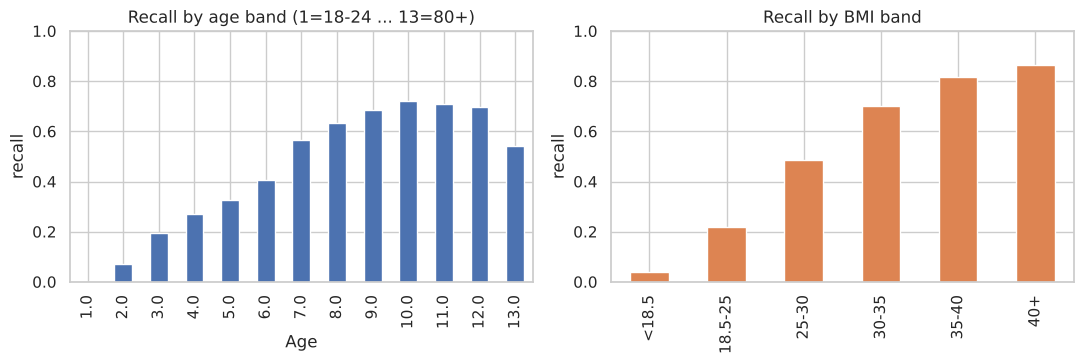

In [32]:
pos = err[err[TARGET] == 1]
age_recall = pos.groupby("Age")["pred"].mean()
bmi_recall = pos.groupby("BMI_cat")["pred"].mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
age_recall.plot(kind="bar", ax=axes[0], color="#4C72B0"); axes[0].set_title("Recall by age band (1=18-24 ... 13=80+)")
bmi_recall.index = ["<18.5", "18.5-25", "25-30", "30-35", "35-40", "40+"][:len(bmi_recall)]
bmi_recall.plot(kind="bar", ax=axes[1], color="#DD8452"); axes[1].set_title("Recall by BMI band")
for ax in axes: ax.set_ylim(0, 1); ax.set_ylabel("recall")
plt.tight_layout(); plt.savefig(FIG_DIR / "recall_by_group.png", dpi=150); plt.show()
pd.DataFrame({"recall_by_age": age_recall}).to_csv(RES_DIR / "recall_by_age.csv")
pd.DataFrame({"recall_by_bmi": bmi_recall}).to_csv(RES_DIR / "recall_by_bmi.csv")

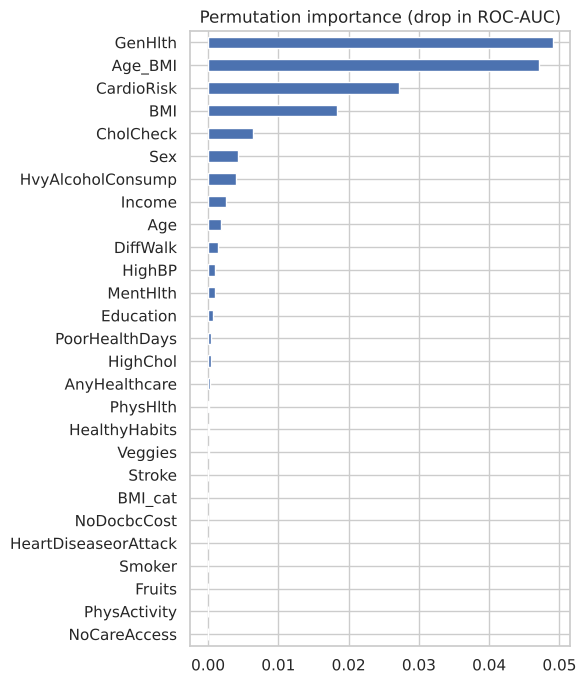

In [33]:
# Which features drive the boosting model? Permutation importance on a validation sample.
from sklearn.inspection import permutation_importance
Xv_s, _, yv_s, _ = train_test_split(X_val_fe, y_val, train_size=10_000, stratify=y_val, random_state=SEED)
perm = permutation_importance(hgb_tuned, Xv_s, yv_s, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=ALL_FEATURES).sort_values()
imp.to_csv(RES_DIR / "permutation_importance.csv")
fig, ax = plt.subplots(figsize=(6, 7))
imp.plot(kind="barh", ax=ax, color="#4C72B0"); ax.set_title("Permutation importance (drop in ROC-AUC)")
plt.tight_layout(); plt.savefig(FIG_DIR / "permutation_importance.png", dpi=150); plt.show()

**Reading the error analysis.** The missed diabetics (FN) look much more like the true negatives than like the caught
cases. They rate their health better (mean `GenHlth` 2.7 against 3.7 for TP), fewer have high blood pressure (53% against
90%), they have lower BMI (28.6 against 34.0), and they have far less difficulty walking. The model has learned the
typical profile of an older, overweight person with type 2 diabetes and cardiovascular risk. People with diabetes who
don't fit that profile get missed. Recall is close to zero for the youngest age bands and for people with normal or low
BMI, and highest for ages 60-74 and BMI above 35. The false positives look very similar to the true positives, so some of
them may be undiagnosed diabetics that the survey labels as 0.

## 10. Saving the best models

The tuned gradient boosting model is saved with `joblib` (together with the BMI cap and feature list it needs).
The neural network is saved in the native Keras format and also as `.h5`. These files go in the Google Drive folder,
not in GitHub.

In [34]:
joblib.dump({"model": hgb_tuned, "features": ALL_FEATURES, "bmi_cap": float(BMI_CAP), "threshold": ml_thr},
            MODEL_DIR / "best_ml_hgb.joblib")
best_dl_model.save(MODEL_DIR / "best_dl_model.keras")
best_dl_model.save(MODEL_DIR / "best_dl_model.h5")
joblib.dump({"input_kind": dl_input_kind, "flat_scaler": scaler_fe, "features": ALL_FEATURES,
             "num_scaler": num_scaler, "num_cols": NUM_COLS, "cat_cols": CAT_COLS, "cat_offsets": cat_offsets,
             "cat_sizes": cat_sizes, "bmi_cap": float(BMI_CAP), "threshold": dl_thr},
            MODEL_DIR / "best_dl_preprocessing.joblib")
print(sorted(p.name for p in MODEL_DIR.iterdir()))

['best_dl_model.h5', 'best_dl_model.keras', 'best_dl_preprocessing.joblib', 'best_ml_hgb.joblib']


## 11. Experiment table and conclusions

The full table below is also saved as `results/experiments.csv` and is the source of the experiment table in the
report. TensorBoard logs for the DL runs can be viewed with `tensorboard --logdir logs`.

In [35]:
exp_table = pd.DataFrame(EXPERIMENTS)
exp_table.to_csv(RES_DIR / "experiments.csv", index=False)
with open(RES_DIR / "experiments.md", "w") as f:
    f.write(exp_table.drop(columns=["family"]).to_markdown(index=False))
exp_table

,id,family,model,features,settings,accuracy,precision,recall,f1,roc_auc,pr_auc,train_time_s,notes
0,ML-1,Traditional ML,LogisticRegression,original (21),"C=1.0, no class weights",0.8526,0.5613,0.1660,0.2563,0.8134,0.4291,0.5,baseline
1,ML-2,Traditional ML,LogisticRegression,original + engineered (27),"C=1.0, class_weight=balanced",0.7224,0.3257,0.7612,0.4562,0.8152,0.4312,1.0,tests imbalance handling + feature engineering
2,ML-3,Traditional ML,RandomForestClassifier,original + engineered (27),"n_estimators=200, min_samples_leaf=5, class_we...",0.7517,0.3458,0.6989,0.4627,0.8108,0.4271,8.9,
3,ML-4,Traditional ML,RandomForestClassifier,original + engineered (27),"RandomizedSearchCV best: {'n_estimators': 200,...",0.7176,0.3234,0.7756,0.4565,0.8169,0.4406,7.1,"tuned on 60k sample, 3-fold CV"
4,ML-5,Traditional ML,HistGradientBoostingClassifier,original + engineered (27),"learning_rate=0.1, max_iter=100, max_leaf_node...",0.8553,0.5971,0.1647,0.2582,0.8200,0.4463,1.3,
5,ML-6,Traditional ML,HistGradientBoostingClassifier,original + engineered (27),RandomizedSearchCV best: {'min_samples_leaf': ...,0.8547,0.5860,0.1702,0.2638,0.8203,0.4468,3.7,"tuned on 60k sample, 3-fold CV"
6,ML-7,Traditional ML,HistGradientBoostingClassifier,top 15 by mutual information,same as ML-6,0.8544,0.5891,0.1596,0.2511,0.8150,0.4394,2.6,feature selection
7,ML-8,Traditional ML,HistGradientBoostingClassifier,original + engineered (27),"ML-6 model, threshold=0.233",0.7901,0.3866,0.6351,0.4806,0.8203,0.4468,0.0,threshold moved from 0.5 to best-F1 value
8,DL-1,Deep Learning,sequential,scaled original + engineered (27),"Sequential 64-32, lr=1e-3, no reg; epochs run=...",0.8520,0.5424,0.2065,0.2991,0.8143,0.4310,58.1,baseline
9,DL-2,Deep Learning,sequential_1,scaled original + engineered (27),"Sequential 256-128-64, lr=1e-3, no reg; epochs...",0.8329,0.4144,0.2249,0.2916,0.7606,0.3404,86.6,capacity test


### Conclusions

_Write 1-2 short paragraphs here in your own words once you have read the results: which family won and by how much,
what helped most (class weighting, tuning, threshold), what the learning curves showed, and the main limitation
(self-reported survey data, one year, prediabetes merged with diabetes)._